# Lab 8: Cosine and Raised-Cosine Pulse Shaping for BPSK

Every symbol you've transmitted so far has been shaped the same way: held flat for its whole
symbol period, then switched instantly to the next value. That rectangular pulse is the
simplest possible choice, but it's a poor one in one specific respect -- an instant jump in
amplitude contains energy at *every* frequency, which means the signal's spectrum trails off
very slowly on either side of the carrier. In a real system sharing spectrum with other users,
that slow rolloff is wasted bandwidth and interference to your neighbors.

This lab builds two smoother alternatives and puts both on the air using BPSK:

- **A cosine pulse.** Instead of switching instantly, ramp the amplitude up and down smoothly
  within each symbol period using a cosine taper. It's still confined to exactly one symbol
  period -- so, just like the rectangular pulse, neighboring symbols never overlap in time --
  but the smoother edges shrink the spectrum's sidelobes noticeably.
- **A raised-cosine pulse.** The classic bandwidth-efficient pulse used in real communication
  systems. Unlike the first two, it deliberately spreads a single symbol's energy across
  *several* neighboring symbol periods. That sounds like it should cause interference between
  symbols -- and if you sample at the wrong instant, it will -- but it's specifically
  engineered so that at the *correct* sampling instant, every neighboring symbol's
  contribution is exactly zero. That's Nyquist's zero-ISI criterion, and getting to see it
  work is the payoff of this lab.

Both pulses plug into the same general shaping-and-matched-filtering machinery -- you'll only
write the pulse shape itself; everything downstream (framing, sync, matched filtering, BER)
handles whichever pulse you hand it, unchanged.

**Hardware note:** This notebook transmits and receives using two ADALM-Pluto SDRs. Set `fc` and the IP addresses in the configuration cell to match your hardware before running the RF cells. The DSP-only cells can be tested separately without transmitting.


## Hardware Configuration

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve, welch
import adi

In [2]:
fs = int(2.0e6)                # Sample rate: 2.0 MHz
fc = int(2.4e9)              # RF carrier: 2.4 GHz (must be supported by both Pluto SDRs)

# --- Frame / waveform parameters -------------------------------------
sps              = 8             # samples per symbol
barker_code      = np.array([1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1], dtype=np.float32)  # Barker-13
preamble_len     = len(barker_code) * sps  # sample count: each Barker chip lasts sps samples
preamble_scale   = 1.5           # preamble amplitude, relative to the payload's unit-average
                                  # symbols
n_bits_per_frame = 128       # single-frame sizing: enough bits for a statistically
                                  # meaningful BER from one frame, no pooling across frames
tx_scale         = 2**14         # DAC full-scale headroom

# --- Raised-cosine pulse parameters (used starting in Part 2) --------
rc_beta = 0.35    # roll-off factor: 0 = narrowest possible bandwidth, slowest-decaying tails;
                  # 1 = widest bandwidth, fastest-decaying tails
rc_span = 6       # how many symbol periods the raised-cosine pulse extends across in total
                  # (3 on either side of its center)

# Connect to the two independent Pluto SDRs
tx_sdr = adi.Pluto("ip:192.168.2.1")
# rx_sdr = adi.Pluto("ip:192.168.3.1")

#################################################
# Config TX
tx_sdr.sample_rate = fs
tx_sdr.tx_lo = fc
tx_sdr.tx_rf_bandwidth = fs
tx_sdr.tx_hardwaregain_chan0 = -40   # dB of attenuation from full scale -- a starting point;
                                      # Task 6 and Task 11 will set this explicitly
tx_sdr.tx_cyclic_buffer = True       # loops the frame so the RX side can't miss it entirely

##########################################
# # Config RX
# rx_sdr.sample_rate = fs
# rx_sdr.rx_lo = fc
# rx_sdr.rx_rf_bandwidth = fs
# rx_sdr.gain_control_mode_chan0 = "manual"
# rx_sdr.rx_hardwaregain_chan0 = 30    # dB, fixed for the whole lab -- every BER comparison in
#                                       # this notebook uses the same receiver operating point,
#                                       # so differences you see come from the pulse shape, not
#                                       # a moving receiver gain

In [3]:
rx_sdr = adi.Pluto("ip:192.168.3.1")

rx_sdr.sample_rate = fs
rx_sdr.rx_lo = fc
rx_sdr.rx_rf_bandwidth = fs
rx_sdr.gain_control_mode_chan0 = "manual"
rx_sdr.rx_hardwaregain_chan0 = 30  

Before doing anything else, it's worth a quick look at what the receiver sees with
nothing deliberately being transmitted -- a basic calibration habit worth keeping regardless
of what the rest of the lab does with the signal.

In [4]:
# Quick calibration check: a short idle capture, no frame in flight. If this power
# looks unreasonably high, sort that out before trusting anything downstream.
rx_sdr.rx_buffer_size = 4096
idle_samples = rx_sdr.rx()
idle_power_db = 10 * np.log10(np.mean(np.abs(idle_samples) ** 2))
print(f"Idle noise floor: {idle_power_db:.1f} dB (power, arbitrary units)")

Idle noise floor: 0.7 dB (power, arbitrary units)


## BPSK Constellation and Bit Mapping

This lab only uses BPSK -- the pulse shape is what's changing, not the modulation -- so the
constellation and the generic bit-mapping helpers are given below rather than re-derived.
`bits_to_symbols` / `symbols_to_bits` read out of `CONSTELLATIONS` / `BITS_PER_SYMBOL`, which
keeps them reusable even though this lab only ever registers one scheme.

In [5]:
CONSTELLATIONS = {
    'BPSK': {'0': -1 + 0j, '1': 1 + 0j},
}
BITS_PER_SYMBOL = {
    'BPSK': 1,
}

def bits_to_symbols(bits, scheme):
    k = BITS_PER_SYMBOL[scheme]
    n_symbols = len(bits) // k
    used_bits = bits[:n_symbols * k]
    groups = used_bits.reshape(n_symbols, k)
    labels = [''.join(str(b) for b in row) for row in groups]
    symbols = np.array([CONSTELLATIONS[scheme][lbl] for lbl in labels], dtype=np.complex64)
    return symbols, used_bits


def symbols_to_bits(rx_symbols, scheme):
    labels = list(CONSTELLATIONS[scheme].keys())
    ideal_points = np.array(list(CONSTELLATIONS[scheme].values()))
    dists = np.abs(rx_symbols[:, None] - ideal_points[None, :])
    winners = np.argmin(dists, axis=1)
    bits = np.array([[int(b) for b in labels[w]] for w in winners]).flatten()
    return bits

## Task 1: Generate Random Bits

Generate the one fixed bit sequence this lab will reuse for every transmission -- rectangular,
cosine, and raised-cosine alike -- so the comparison at the end is on equal footing.

In [6]:
def generate_bits(n):
    return np.random.randint(0, 2, n)

tx_bits = generate_bits(n_bits_per_frame)
print(tx_bits.shape, tx_bits[:20])

(128,) [1 0 1 1 0 0 1 1 0 1 0 0 0 0 1 0 1 0 1 1]


## Part 1: A Smoother Alternative -- the Cosine Pulse

A quick note on naming before starting: "raised cosine" gets used for two different things in
this field, which trips people up constantly. The taper you're about to build in Task 2 is
sometimes casually called a "raised-cosine window" -- and it does look like one -- but that's
a different animal from the "raised-cosine pulse" in Part 2, which is a specific pulse
designed to satisfy Nyquist's zero-ISI criterion. To keep the two straight, this lab just
calls the first one **the cosine pulse**, full stop, and saves "raised cosine" for Part 2.

## Task 2: The Cosine Pulse

The rectangular pulse jumps from 0 to its full value instantly at the start of every symbol,
and back down just as abruptly at the end. The cosine pulse replaces both jumps with a smooth
taper that touches exactly zero at both edges and rises to its peak in the middle:

$$g[n] = \tfrac{1}{2}\left(1 - \cos\left(\dfrac{2\pi n}{\text{sps} - 1}\right)\right), \qquad
n = 0, 1, \dots, \text{sps}-1$$

`cosine_pulse(sps)` below builds this as an array. Your one job is the formula itself --
`np.arange(sps)` already gives you `n = 0, 1, ..., sps-1`, so the rest is a direct
translation of the equation above into NumPy.

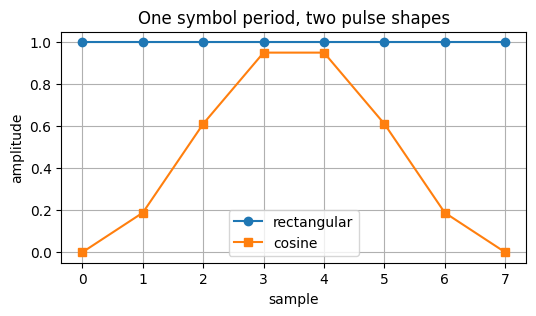

In [7]:
def rect_pulse(sps):
    '''The rectangular pulse: sps samples, all equal to 1.'''
    return np.ones(sps)


def cosine_pulse(sps):
    '''
    TODO: one line, following the formula above. n is given.
    '''
    n = np.arange(sps)
    pulse = 0.5 * (1 - np.cos(2 * np.pi * n / (sps - 1)))
    return pulse


plt.figure(figsize=(6, 3))
plt.plot(rect_pulse(sps), 'o-', label='rectangular')
plt.plot(cosine_pulse(sps), 's-', label='cosine')
plt.xlabel('sample')
plt.ylabel('amplitude')
plt.title("One symbol period, two pulse shapes")
plt.legend()
plt.grid(True)
plt.show()

## Task 3: General Pulse Shaping and Matched Filtering

Rather than writing separate shaping code for each pulse, it's worth building this once in a
form that works for *any* pulse you hand it -- rectangular, cosine, or (in Part 2) something
much longer. `pulse_shape(symbols, pulse, sps)` does this by zero-stuffing your symbols (one
nonzero sample every `sps` samples, matching each symbol's timing) and convolving the result
with the pulse -- given below in full, since it's the same idea regardless of pulse shape.

`matched_filter_downsample(samples, pulse, sps)` is the receive-side counterpart: correlate
against the *matched* kernel (the pulse, reversed and conjugated), then keep one output sample
per symbol. Your one job is the kernel itself:

$$\text{kernel} = \dfrac{\text{conj}(\text{pulse reversed})}{\sum |\text{pulse}|^2}$$

The denominator matters: without it, the matched filter's output would be scaled by the
pulse's own energy instead of landing back on the transmitted symbol's actual amplitude.

Important timing detail: `pulse_shape` uses full convolution, so the receive filter must
compensate the combined pulse delay exactly. One detail that's easy to miss and worth stating
plainly: the downsampling index below is
`len(pulse) - 1`, not `sps - 1`. For the rectangular and cosine pulses those are the same
number, since both pulses are exactly `sps` samples long -- but Part 2's raised-cosine pulse
will be much longer than one symbol period, and this same formula (and the same two
functions) will still work correctly, unchanged, once you get there.

**Timing convention:** the transmitter uses full convolution. The matched-filter peak for the first symbol occurs at `len(pulse)-1` samples after the payload starts, so the downsampler starts there. For long RRC pulses, the waveform and capture must include the filter tail.


In [8]:
def pulse_shape(symbols, pulse, sps):
    n_symbols = len(symbols)
    zero_stuffed = np.zeros(n_symbols * sps, dtype=complex)
    zero_stuffed[0::sps] = symbols
    shaped = np.convolve(zero_stuffed, pulse)   # full convolution -- keep every sample,
                                                  # including the tail past the last symbol
                                                  # (matters once pulses get longer than one
                                                  # symbol period, in Part 2)
    return shaped


def matched_filter_downsample(samples, pulse, sps):
    '''
    TODO: one line. kernel = conj(reversed pulse) / (pulse energy) -- see the formula above.
    '''
    kernel = np.conj(pulse[::-1]) / np.sum(np.abs(pulse) ** 2)
    filtered = np.convolve(samples, kernel)
    delay = len(pulse) - 1
    # The first valid symbol decision occurs at the matched-filter peak delay.
    # For a pulse of length L, that peak is at L-1 in the full convolution.
    return filtered[delay::sps]


# Sanity check: shape a few symbols with the cosine pulse, matched-filter them back, and
# confirm you recover (approximately) the original symbol values.
test_symbols = np.array([1 + 0j, -1 + 0j, 1 + 0j, -1 + 0j])
test_pulse = cosine_pulse(sps)
shaped = pulse_shape(test_symbols, test_pulse, sps)
recovered = matched_filter_downsample(shaped, test_pulse, sps)
print("Transmitted:", test_symbols)
print("Recovered:  ", np.round(recovered[:len(test_symbols)], 3))
assert np.allclose(recovered[:len(test_symbols)], test_symbols, atol=1e-6), \
    "Matched-filter timing/normalization is incorrect for this pulse."

Transmitted: [ 1.+0.j -1.+0.j  1.+0.j -1.+0.j]
Recovered:   [ 1.+0.j -1.+0.j  1.+0.j -1.+0.j]


## Task 4: Frame Construction, Transmit, and Capture

The frame begins with a **Barker-13 training sequence**. Each of the 13 chips (+1/-1) is held for `sps` samples, giving a known sample-level template for normalized correlation-based frame detection and channel/CFO estimation. The pulse-shaped BPSK payload follows the preamble.

In [9]:
def make_barker_preamble(sps, scale):
    """Barker-13 known training sequence, each chip held for sps samples."""
    chips = np.asarray(barker_code, dtype=np.complex64)
    return (np.repeat(chips, sps) * scale).astype(np.complex64)


def build_tx_frame(bits, pulse, sps, preamble_len, preamble_scale):
    data_symbols, used_bits = bits_to_symbols(bits, 'BPSK')
    payload = pulse_shape(data_symbols, pulse, sps)

    preamble = make_barker_preamble(sps, preamble_scale)
    if len(preamble) != preamble_len:
        raise ValueError(f"Barker preamble length mismatch: {len(preamble)} != {preamble_len}")

    frame = np.concatenate([preamble, payload]).astype(np.complex64) * tx_scale
    return frame, used_bits


def frame_len_for(n_symbols, pulse_len, preamble_len, sps):
    # Preamble is a known sample sequence; payload is causal pulse-shaped data.
    return preamble_len + n_symbols * sps + pulse_len - 1


def buffer_size_for(frame_len, margin=2.2):
    return int(np.ceil(margin * frame_len))


def capture(tx_frame, buffer_size, settle=0.5, flush=5):
    rx_sdr.rx_buffer_size = buffer_size
    try:
        tx_sdr.tx_destroy_buffer()
    except Exception:
        pass
    tx_sdr.tx(tx_frame)
    time.sleep(settle)
    for _ in range(flush):
        _ = rx_sdr.rx()
    rx_samples = np.asarray(rx_sdr.rx()).ravel()
    if len(rx_samples) < buffer_size:
        print(
            f"WARNING: Pluto returned {len(rx_samples)} samples, but {buffer_size} were requested. "
            "Frame length must fit in the actual capture."
        )
    return rx_samples


# Demo: build one BPSK frame using the cosine pulse, transmit, capture
cos_pulse_arr = cosine_pulse(sps)
demo_frame, demo_used_bits = build_tx_frame(tx_bits, cos_pulse_arr, sps, preamble_len, preamble_scale)
demo_frame_len = frame_len_for(len(demo_used_bits), len(cos_pulse_arr), preamble_len, sps)
print("Barker-13 preamble samples:", preamble_len, "sample rate:", fs)


Barker-13 preamble samples: 104 sample rate: 2000000


## Task 5: Frame Synchronization and Correction

The preamble is a constant complex tone (one repeated sample value), so a carrier-frequency offset rotates its phase from sample to sample. A plain coherent sum can fail when that phase rotates. `find_frame_start` therefore uses adjacent-sample differential phase coherence, which is robust to a constant CFO. It searches only positions where the full frame fits in the capture.

`correct_frame` estimates CFO from the preamble's adjacent-sample phase increment, removes it, and then estimates preamble phase and amplitude. The BER routine now refuses to silently truncate unequal bit arrays.

**Important:** restart the kernel and run every cell from the top. Old notebook state can otherwise mix 120,000 old TX bits with a newly configured short frame.

**Fine carrier tracking:** after coarse CFO/phase correction and matched filtering, a symbol-rate BPSK Costas loop tracks residual phase/frequency drift. Preamble-based correction is still needed for coarse acquisition and to resolve BPSK's 180-degree phase ambiguity.


In [10]:
def find_frame_start(rx_samples, preamble_len, frame_len, search_stride=None):
    """Find the known Barker-13 sample pattern by normalized complex correlation."""
    x = np.asarray(rx_samples).ravel().astype(np.complex128)
    template = make_barker_preamble(sps, preamble_scale).astype(np.complex128)
    if len(template) != preamble_len:
        raise ValueError("Barker template length does not match preamble_len.")
    if frame_len > len(x):
        raise ValueError(f"Capture too short: {len(x)} samples, frame requires {frame_len}.")

    # Matched correlation, normalized by local receive energy to reduce gain sensitivity.
    corr = fftconvolve(x, np.conj(template[::-1]), mode="valid")
    energy = fftconvolve(np.abs(x)**2, np.ones(len(template)), mode="valid").real
    template_energy = np.sum(np.abs(template)**2)
    score = np.abs(corr) / np.sqrt(np.maximum(energy * template_energy, 1e-20))

    # Require the entire frame to fit in the capture.
    max_start = len(x) - frame_len
    score[max_start + 1:] = -np.inf
    start = int(np.argmax(score))
    if not np.isfinite(score[start]) or score[start] < 0.2:
        raise ValueError(
            f"Barker preamble correlation too low (score={score[start]:.3f}). "
            "Check TX/RX frequency, gain, capture length and timing."
        )
    print(f"Barker sync correlation={score[start]:.3f}")
    return start


def correct_frame(frame_slice, preamble_len, preamble_symbol, preamble_scale, fs):
    """Use known Barker samples for coarse CFO, phase and gain correction."""
    x = np.asarray(frame_slice).ravel().astype(np.complex128)
    template = make_barker_preamble(sps, preamble_scale).astype(np.complex128)
    if len(x) <= preamble_len or len(template) != preamble_len:
        raise ValueError("Frame/preamble length mismatch or no payload after preamble.")

    pre = x[:preamble_len]
    # Divide out the known Barker waveform. Its phase transitions are removed,
    # leaving the carrier's approximately linear phase progression.
    valid = np.abs(template) > 1e-12
    ratio = pre[valid] / template[valid]
    sample_idx = np.flatnonzero(valid).astype(float)
    phase_unwrapped = np.unwrap(np.angle(ratio))
    # Least-squares slope is less noisy than adjacent-sample phase estimates.
    slope, intercept = np.polyfit(sample_idx, phase_unwrapped, 1)
    f_offset_hat = slope * fs / (2 * np.pi)

    n = np.arange(len(x), dtype=float)
    cfo_corrected = x * np.exp(-1j * 2 * np.pi * f_offset_hat * n / fs)
    pre_corrected = cfo_corrected[:preamble_len]
    ref_ratio = pre_corrected[valid] / template[valid]
    channel = np.mean(ref_ratio)
    if abs(channel) < 1e-12:
        raise ValueError("Barker channel estimate is near zero.")
    phase_offset_hat = np.angle(channel)
    gain_hat = np.abs(channel)
    corrected = cfo_corrected / channel
    return corrected, f_offset_hat, phase_offset_hat, gain_hat


In [11]:
# Receiver sanity checks: run_trial prints sync/CFO/phase/gain and enforces exact BER lengths.
# Barker-13 synchronization prints its normalized correlation score. If BER remains near 0.5, inspect this score, CFO/gain estimates, constellation, TX/RX LO and RF gain.
print("Current configuration:")
print(f"fs={fs}, sps={sps}, preamble_len={preamble_len}, n_bits_per_frame={n_bits_per_frame}")
print("BPSK mapping: 0 -> -1, 1 -> +1")


Current configuration:
fs=2000000, sps=8, preamble_len=104, n_bits_per_frame=128
BPSK mapping: 0 -> -1, 1 -> +1


## Task 6: Single-Frame BER With the Cosine Pulse

`compute_ber` and `run_trial` are given below -- `run_trial` wraps Tasks 3-5 into one
repeatable call: build a frame with whichever pulse you hand it, transmit at a given TX gain,
capture, sync, correct, matched-filter, and score. Your one job is the call itself.

In [12]:

def costas_loop_bpsk(symbols, loop_bandwidth=0.02, damping=0.707):
    """
    Symbol-rate decision-directed BPSK Costas loop for fine residual carrier
    phase/frequency tracking. Input must be matched-filtered and coarsely
    frequency/phase corrected. Returns corrected symbols and phase history.
    """
    x = np.asarray(symbols, dtype=np.complex128).ravel()
    if not len(x):
        return x.copy(), np.array([], dtype=float)

    zeta = float(damping)
    wn = float(loop_bandwidth) / (zeta + 1.0 / (4.0 * zeta))
    alpha = 2.0 * zeta * wn
    beta = wn * wn
    phase = 0.0
    freq = 0.0
    out = np.empty_like(x)
    phases = np.empty(len(x), dtype=float)

    for k, sample in enumerate(x):
        y = sample * np.exp(-1j * phase)
        out[k] = y
        phases[k] = phase
        scale = max(abs(y), 1e-12)
        error = np.sign(y.real) * y.imag / scale
        freq += beta * error
        phase += freq + alpha * error
        phase = (phase + np.pi) % (2 * np.pi) - np.pi

    return out, phases


def compute_ber(tx_bits, rx_bits):
    """Strict BER: never silently compare only a truncated prefix."""
    tx_bits = np.asarray(tx_bits).astype(int).ravel()
    rx_bits = np.asarray(rx_bits).astype(int).ravel()
    if len(tx_bits) != len(rx_bits):
        raise ValueError(
            f"BER comparison invalid: {len(tx_bits)} TX bits but {len(rx_bits)} RX bits. "
            "Check frame start, matched-filter delay, and payload extraction."
        )
    if len(tx_bits) == 0:
        raise ValueError("Cannot compute BER on an empty bit sequence.")
    errors = int(np.count_nonzero(tx_bits != rx_bits))
    return errors, len(tx_bits), errors / len(tx_bits)


def run_trial(pulse, tx_gain_db, tx_bits):
    tx_frame, used_bits = build_tx_frame(tx_bits, pulse, sps, preamble_len, preamble_scale)
    frame_len = frame_len_for(len(used_bits), len(pulse), preamble_len, sps)

    tx_sdr.tx_hardwaregain_chan0 = tx_gain_db
    time.sleep(0.1)
    rx_samples = capture(tx_frame, buffer_size_for(frame_len))

    start = find_frame_start(rx_samples, preamble_len, frame_len)
    frame_slice = rx_samples[start:start + frame_len]
    if len(frame_slice) != frame_len:
        raise ValueError(f"Detected frame is truncated: {len(frame_slice)} / {frame_len} samples")

    corrected, f_hat, phi_hat, g_hat = correct_frame(
        frame_slice, preamble_len, 1 + 0j, preamble_scale, fs
    )

    # Remove the sample-wise preamble. For causal pulse shaping, the matched
    # filter's peak for the first symbol is at len(pulse)-1 samples.
    payload_samples = corrected[preamble_len:]
    rx_syms_all = matched_filter_downsample(payload_samples, pulse, sps)
    n_symbols = len(used_bits)  # BPSK: one bit per symbol

    # Keep exactly the transmitted payload symbol count. The strict BER check
    # below ensures this is not accidentally compared with unrelated bits.
    if len(rx_syms_all) < n_symbols:
        raise ValueError(
            f"Matched filter produced only {len(rx_syms_all)} symbols for "
            f"{n_symbols} transmitted bits. Check capture length and filter delay."
        )
    rx_syms = rx_syms_all[:n_symbols]
    # Fine residual carrier phase/frequency tracking after matched filtering.
    rx_syms, costas_phase = costas_loop_bpsk(rx_syms, loop_bandwidth=0.02)
    rx_bits = symbols_to_bits(rx_syms, 'BPSK')

    tx_sdr.tx_destroy_buffer()
    errors, total, ber = compute_ber(used_bits, rx_bits)
    final_phase = costas_phase[-1] if len(costas_phase) else 0.0
    print(f"Sync start={start}, CFO={f_hat:.1f} Hz, phase={phi_hat:.3f} rad, "
          f"gain={g_hat:.4g}, Costas final phase={final_phase:.3f} rad, "
          f"RX symbols={len(rx_syms)}, errors={errors}/{total}")
    return ber, total, rx_syms


In [13]:
# Software-only Costas-loop sanity test (does not use SDR hardware).
# A known BPSK sequence with residual phase/frequency drift should be recovered.
_rng = np.random.default_rng(7)
_test_bits = _rng.integers(0, 2, 1000)
_test_symbols = 2 * _test_bits - 1
_test_n = np.arange(len(_test_symbols))
_test_rx = _test_symbols * np.exp(1j * (0.4 + 0.01 * _test_n))
_test_corrected, _test_phase = costas_loop_bpsk(_test_rx, loop_bandwidth=0.02)
_test_ber = np.mean((_test_corrected.real > 0) != (_test_bits > 0))
print(f"Costas-loop synthetic test BER: {_test_ber:.4f}")
assert _test_ber < 0.01, "Costas loop failed the synthetic residual-phase test."


Costas-loop synthetic test BER: 0.0000


## Part 2: The Root-Raised-Cosine Pulse

The cosine pulse helped, but it's still confined to exactly one symbol period, which limits
how smooth it can be. Real bandwidth-efficient systems go a step further: let a single
symbol's pulse spread out over *several* symbol periods, so its edges can taper far more
gradually than anything squeezed into one symbol period alone.

Spreading a pulse across several symbols sounds like it should immediately cause
inter-symbol interference (ISI) -- neighboring symbols' pulses now genuinely overlap in time.
The root-raised-cosine pulse is the classic solution to that problem: it's shaped so that, sampled
at exactly the right instant, every neighboring symbol's contribution is precisely zero. Only
the pulse's own peak survives at its own sampling instant. This is Nyquist's zero-ISI
criterion in action, and Task 9 will let you check it directly.

## Task 7: Build the Root-Raised-Cosine Pulse

For a transmitter and matched-filter receiver, use a **root-raised-cosine (RRC)** pulse at
both ends. The cascade of the transmit and receive filters is a raised-cosine response, which
satisfies the zero-ISI criterion. Using a raised-cosine pulse at both ends would square its
frequency response and generally introduce ISI.

With $t$ measured in symbol periods and roll-off $\\beta$, the RRC pulse is

$$g(t)=\\frac{\\sin(\\pi t(1-\\beta))+4\\beta t\\cos(\\pi t(1+\\beta))}
{\\pi t[1-(4\\beta t)^2]}.$$

The expression has removable singularities at $t=0$ and $t=\\pm1/(4\\beta)$. The code below
handles those special cases and evaluates the general formula everywhere else.


In [14]:
def raised_cosine_pulse(sps, beta, span):
    """Return a unit-peak root-raised-cosine (RRC) pulse, sampled at sps."""
    if sps < 2 or span < 2 or not (0 <= beta <= 1):
        raise ValueError("Require sps >= 2, span >= 2, and 0 <= beta <= 1.")

    n = np.arange(-span * sps // 2, span * sps // 2 + 1)
    t = n / sps
    g = np.zeros_like(t, dtype=float)

    if beta == 0:
        # beta=0 reduces to sinc(t).
        g = np.sinc(t)
        return g

    at_zero = np.isclose(t, 0.0, atol=1e-12)
    at_singular = np.isclose(np.abs(t), 1 / (4 * beta), atol=1e-12)
    general = ~(at_zero | at_singular)

    g[at_zero] = 1 + beta * (4 / np.pi - 1)

    ts = 1 / (4 * beta)
    g[at_singular] = (beta / np.sqrt(2) *
        ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) +
         (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta))))

    tg = t[general]
    g[general] = (
        np.sin(np.pi * tg * (1 - beta)) +
        4 * beta * tg * np.cos(np.pi * tg * (1 + beta))
    ) / (np.pi * tg * (1 - (4 * beta * tg) ** 2))

    return g


rc_pulse_arr = raised_cosine_pulse(sps, rc_beta, rc_span)
print(f"RRC pulse length: {len(rc_pulse_arr)} samples ({rc_span} symbol periods, "
      f"center at index {len(rc_pulse_arr)//2})")


RRC pulse length: 49 samples (6 symbol periods, center at index 24)


## Task 8: Compare All Three Pulses, Time and Frequency

Given in full -- run it and look at both plots before moving on. Time domain: the raised-
cosine pulse visibly extends well beyond one symbol period on either side, unlike the other
two. Frequency domain: the three pulses carry the same symbol rate, but occupy noticeably
different bandwidths -- the rectangular pulse's spectrum trails off the slowest, the cosine
pulse's a bit faster, and the root-raised-cosine pulse's the fastest of all, with a rolloff
controlled directly by $\beta$.

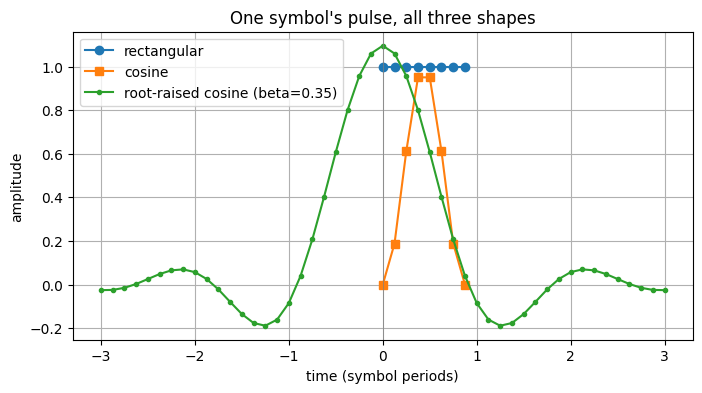

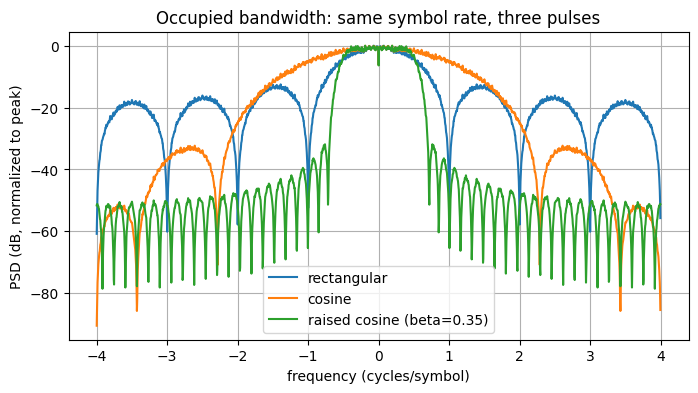

In [15]:
rect_pulse_arr = rect_pulse(sps)

# --- Time domain ---
plt.figure(figsize=(8, 4))
t_short = np.arange(sps) / sps
t_rc = (np.arange(len(rc_pulse_arr)) - len(rc_pulse_arr) // 2) / sps
plt.plot(t_short, rect_pulse_arr, 'o-', label='rectangular')
plt.plot(t_short, cos_pulse_arr, 's-', label='cosine')
plt.plot(t_rc, rc_pulse_arr, '.-', label=f'root-raised cosine (beta={rc_beta})')
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('time (symbol periods)')
plt.ylabel('amplitude')
plt.title("One symbol's pulse, all three shapes")
plt.legend()
plt.grid(True)
plt.show()

# --- Frequency domain: PSD of a noise-free transmitted BPSK waveform, each pulse ---
demo_bits = generate_bits(20_000)
demo_symbols, _ = bits_to_symbols(demo_bits, 'BPSK')

plt.figure(figsize=(8, 4))
for pulse, label in [(rect_pulse_arr, 'rectangular'),
                      (cos_pulse_arr, 'cosine'),
                      (rc_pulse_arr, f'raised cosine (beta={rc_beta})')]:
    waveform = pulse_shape(demo_symbols, pulse, sps)
    f, psd = welch(waveform, fs=sps, nperseg=2048, return_onesided=False)
    f, psd = np.fft.fftshift(f), np.fft.fftshift(psd)
    plt.plot(f, 10 * np.log10(psd / psd.max()), label=label)
plt.xlabel('frequency (cycles/symbol)')
plt.ylabel('PSD (dB, normalized to peak)')
plt.title('Occupied bandwidth: same symbol rate, three pulses')
plt.legend()
plt.grid(True)
plt.show()

## Task 9: Confirm the Zero-ISI Property

The RRC pulse alone does not have zero crossings at every symbol interval. The **combined
transmit pulse and matched filter** does: convolving the RRC pulse with its time-reversed
conjugate gives a raised-cosine-like response with zero crossings at nonzero symbol offsets.
The check below samples that combined response at symbol intervals.


In [16]:
# Combined response of the transmit RRC pulse and receive matched filter.
combined = np.convolve(rc_pulse_arr, np.conj(rc_pulse_arr[::-1]))
combined = combined / np.max(np.abs(combined))
center = len(combined) // 2
offsets = np.arange(-(rc_span // 2), rc_span // 2 + 1)
sample_indices = center + offsets * sps

print("Combined RRC + matched-filter response, sampled at symbol periods:")
for k, idx in zip(offsets, sample_indices):
    print(f"  {k:+d} symbol periods from center: {combined[idx]: .4f}")


Combined RRC + matched-filter response, sampled at symbol periods:
  -3 symbol periods from center:  0.0010
  -2 symbol periods from center:  0.0001
  -1 symbol periods from center:  0.0007
  +0 symbol periods from center:  1.0000
  +1 symbol periods from center:  0.0007
  +2 symbol periods from center:  0.0001
  +3 symbol periods from center:  0.0010


## Task 10: The Root-Raised-Cosine Pulse on the Air

Given in full -- every function from Part 1 (`build_tx_frame`, `capture`, `find_frame_start`,
`correct_frame`, `matched_filter_downsample`) already handles an arbitrary-length pulse, so
switching to the root-raised-cosine pulse is just a matter of passing `rc_pulse_arr` in instead.
This builds one frame, transmits, captures, corrects, and plots the received constellation --
confirm your BPSK symbols still land in two tight clusters at $\pm 1$, same as with the
cosine pulse in Task 5, despite the much longer pulse now in play.

Barker sync correlation=0.898


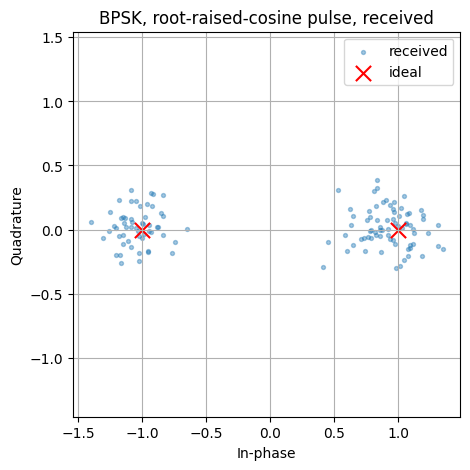

In [17]:
rc_frame, rc_used_bits = build_tx_frame(tx_bits, rc_pulse_arr, sps, preamble_len, preamble_scale)
rc_frame_len = frame_len_for(len(rc_used_bits), len(rc_pulse_arr), preamble_len, sps)
rc_rx_samples = capture(rc_frame, buffer_size_for(rc_frame_len))

rc_start = find_frame_start(rc_rx_samples, preamble_len, rc_frame_len)
rc_frame_slice = rc_rx_samples[rc_start:rc_start + rc_frame_len]
rc_corrected, *_ = correct_frame(rc_frame_slice, preamble_len, 1 + 0j, preamble_scale, fs)
rc_rx_syms = matched_filter_downsample(rc_corrected[preamble_len:], rc_pulse_arr, sps)
rc_rx_syms, rc_costas_phase = costas_loop_bpsk(rc_rx_syms[:len(tx_bits)], loop_bandwidth=0.02)

plt.figure(figsize=(5, 5))
plt.scatter(rc_rx_syms.real, rc_rx_syms.imag, s=8, alpha=0.4, label='received')
ideal = np.array(list(CONSTELLATIONS['BPSK'].values()))
plt.scatter(ideal.real, ideal.imag, s=120, marker='x', c='red', label='ideal')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('In-phase'); plt.ylabel('Quadrature')
plt.title('BPSK, root-raised-cosine pulse, received')
plt.show()

## Task 11: Single-Frame BER With the Root-Raised-Cosine Pulse, and the Full Comparison

Same `run_trial` call as Task 6, just with the root-raised-cosine pulse this time. The cell below
also reruns the rectangular pulse once for reference and prints all three BERs side by side --
given in full, since it's pure bookkeeping at this point.

In [18]:
# Software-only test: Barker sync and CFO/channel correction with a known delay.
# This does not transmit over SDR hardware.
_test_preamble = make_barker_preamble(sps, preamble_scale).astype(complex)
_test_payload_bits = np.array([0, 1, 1, 0, 1, 0, 0, 1], dtype=int)
_test_payload_syms, _ = bits_to_symbols(_test_payload_bits, "BPSK")
_test_payload = pulse_shape(_test_payload_syms, cosine_pulse(sps), sps)
_test_frame = np.concatenate([_test_preamble, _test_payload]).astype(complex)
_test_delay = 37
_test_cfo = 1800.0
_test_phase = 0.63
_test_gain = 0.7
_test_n = np.arange(len(_test_frame))
_test_rx_frame = _test_gain * _test_frame * np.exp(
    1j * (2*np.pi*_test_cfo*_test_n/fs + _test_phase)
)
_test_capture = np.concatenate([
    np.zeros(_test_delay, dtype=complex),
    _test_rx_frame,
    np.zeros(len(_test_frame), dtype=complex)
])
_test_frame_len = len(_test_frame)
_test_start = find_frame_start(_test_capture, preamble_len, _test_frame_len)
_test_slice = _test_capture[_test_start:_test_start + _test_frame_len]
_test_corrected, _test_fhat, _test_phihat, _test_ghat = correct_frame(
    _test_slice, preamble_len, 1 + 0j, preamble_scale, fs
)
print(f"Expected start={_test_delay}, detected={_test_start}")
print(f"Expected CFO={_test_cfo:.1f} Hz, estimated={_test_fhat:.1f} Hz")
print(f"Expected gain={_test_gain:.2f}, estimated={_test_ghat:.2f}")
assert _test_start == _test_delay, "Barker frame synchronization test failed"
assert abs(_test_fhat - _test_cfo) < 100, "Barker CFO estimate test failed"
assert abs(_test_ghat - _test_gain) < 0.05, "Barker gain estimate test failed"
print("Barker sync/CFO/channel-estimation software test passed.")


Barker sync correlation=0.986
Expected start=37, detected=37
Expected CFO=1800.0 Hz, estimated=1800.0 Hz
Expected gain=0.70, estimated=0.70
Barker sync/CFO/channel-estimation software test passed.


In [19]:
# Run each pulse at the same TX gain for a fair comparison.
# Adjust this value only after confirming the receiver is not clipping or near its noise floor.
tx_gain_db = -40

ber_rect, total_rect, rx_syms_rect = run_trial(rect_pulse_arr, tx_gain_db, tx_bits)
ber_cos, total_cos, rx_syms_cos = run_trial(cos_pulse_arr, tx_gain_db, tx_bits)
ber_rc, total_rc, rx_syms_rc = run_trial(rc_pulse_arr, tx_gain_db, tx_bits)

print(f"{'pulse':<20}{'BER':>12}{'bits':>12}")
print(f"{'rectangular':<20}{ber_rect:>12.4f}{total_rect:>12d}")
print(f"{'cosine':<20}{ber_cos:>12.4f}{total_cos:>12d}")
print(f"{'root-raised cosine':<20}{ber_rc:>12.4f}{total_rc:>12d}")


Barker sync correlation=0.872
Sync start=2152, CFO=-3835.2 Hz, phase=1.907 rad, gain=1.86, Costas final phase=1.084 rad, RX symbols=128, errors=0/128
Barker sync correlation=0.899
Sync start=2136, CFO=-3623.4 Hz, phase=-1.682 rad, gain=1.895, Costas final phase=0.380 rad, RX symbols=128, errors=0/128
Barker sync correlation=0.906
Sync start=2115, CFO=-3650.4 Hz, phase=1.902 rad, gain=1.906, Costas final phase=0.446 rad, RX symbols=128, errors=0/128
pulse                        BER        bits
rectangular               0.0000         128
cosine                    0.0000         128
root-raised cosine        0.0000         128


## Background

**Why sharp edges cost bandwidth.** A signal's spectrum is its Fourier transform, and an
instantaneous jump in amplitude -- exactly what the rectangular pulse does at every symbol
boundary -- requires energy at arbitrarily high frequencies to reproduce. Formally, the
Fourier transform of a rectangular pulse of duration $T$ is a sinc function, whose sidelobes
decay only as $1/f$: slowly enough that a real system has to either accept significant
out-of-band leakage or filter it away after the fact. The cosine pulse's edges are smoother --
its value and slope both go to zero at the boundary -- and that extra smoothness is exactly
why its spectrum decays faster than the rectangular pulse's. It's still confined to one symbol
period, though, so there's a limit to how smooth its edges can be, and its spectrum still has
more energy far from the carrier than a real bandwidth-constrained system would like.

**Nyquist's zero-ISI criterion.** The raised-cosine pulse takes a completely different
approach: instead of confining the pulse to one symbol period, let it spread across several,
but design it so that at every *other* symbol's sampling instant, its value is exactly zero.
Task 9 confirmed exactly this. That's Nyquist's criterion for ISI-free transmission -- a pulse
doesn't need to be zero everywhere outside its own symbol period, it only needs to cross zero
at every *other* symbol's sampling instant. Sample at the wrong time, even by a fraction of a
symbol period, and that zero-crossing property is lost -- neighboring symbols' tails no longer
cancel, and you get real interference. This is exactly why frame sync (Task 5's job, all lab)
matters as much as it does: a raised-cosine pulse is far less forgiving of timing error than a
rectangular one.

**The role of $\beta$.** The roll-off factor trades bandwidth against time-domain decay.
$\beta \to 0$ gives the narrowest possible bandwidth (approaching the ideal $\text{sinc}$
pulse) but the raised-cosine pulse's tails decay very slowly in that limit, making it
extremely sensitive to timing error. $\beta \to 1$ gives the fastest-decaying tails -- more
forgiving of timing error -- at the cost of using roughly twice the bandwidth of the
zero-roll-off case. Real systems pick something in between (0.35 in this lab, a value used in
several real standards) as a practical compromise.

**One thing to flag for later, not required here:** using the raised-cosine pulse itself as
the matched filter (as this lab does) is one valid choice, but it's not the only one. Splitting
the raised-cosine response evenly between transmitter and receiver -- each side applying a
*square-root* raised-cosine pulse -- is what most real systems actually do, and it has real
advantages once channel effects beyond thermal noise are in the picture. Worth keeping in mind
if you go further in this area, but nothing in this lab depends on it.

## Reflection Questions

1. Why does the rectangular pulse's instant on/off transition lead to a spectrum that decays
   so slowly with frequency?
2. The cosine pulse tapers smoothly to zero at both edges. Does that completely eliminate
   spectral leakage outside the symbol's nominal bandwidth, or just reduce it? Why?
3. The raised-cosine pulse deliberately spreads one symbol's energy across several neighboring
   symbol periods -- yet Task 9 showed no interference at the correct sampling instant. In
   your own words, why doesn't the overlap in time cause a problem?
4. Suppose the receiver sampled the raised-cosine matched-filter output slightly off from the
   correct instant -- not exactly at the peak. Would every value of $\beta$ be equally
   forgiving of that timing error, or would some be more sensitive than others?
5. All three pulses in this lab were normalized so that BPSK's matched-filter output lands on
   the same $\pm 1$ regardless of which pulse was used, and Task 11's BER numbers came out
   close to each other as a result. Given that, what's actually being bought by moving to a
   more complicated pulse than the rectangular one?

## Reflection Questions — Answers

**1. Why does the rectangular pulse's spectrum decay slowly?**  
A rectangular pulse changes instantly at its edges. These sharp transitions create stronger high-frequency components, so its spectrum decays slowly and spreads farther in frequency.

**2. Does the cosine pulse completely eliminate spectral leakage?**  
No. It reduces leakage because its edges taper smoothly to zero, creating fewer sharp changes than a rectangular pulse. However, some energy still exists outside the nominal bandwidth.

**3. Why doesn't the raised-cosine pulse's time overlap cause interference at the sampling instant?**  
The pulse is designed to satisfy the **zero-ISI condition**: at the correct sampling instant, contributions from neighboring symbols are zero. The pulses overlap between sampling instants, but they do not interfere at the ideal decision points.

**4. Are all values of β equally forgiving of timing errors?**  
No. The roll-off factor β changes the pulse shape and its slope near the sampling instant. A larger β often gives a wider, smoother pulse and can be more tolerant of small timing errors, though the exact tolerance depends on the pulse and system.

**5. What do we gain by using a more complex pulse?**  
The main benefit is better bandwidth control and reduced out-of-band energy, helping limit interference with neighboring channels. The rectangular pulse is simpler, but its spectrum spreads more widely. Raised-cosine/RRC shaping offers a useful trade-off between bandwidth, timing behavior, and implementation complexity.